# 05 Features, all 35 (offline)

Code: `src/features.py`, `src/quality.py`. Labels as DREAMT gives them.

Per scored 30 s epoch: time-domain HRV, frequency HRV (5-minute centred window, Lomb-Scargle), motion, TEMP, EDA. **Epochs failing the quality gate keep the epoch but get NaN heart features (option a, provisional).** Then per-person z-scoring over the whole night, then context (mean of previous 4 and next 4 epochs). Missing stays NaN.

Output: `data/derived/features_all35.csv` (inside this project, gitignored) plus the Config beside it.

In [1]:
import os
%load_ext autoreload
%autoreload 2
import sys, gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT / "src"))
from config import Config
from recording import Recording
from preprocess import find_wristband_files
from quality import epoch_quality, quality_gate
from features import epoch_hrv, freq_features, signal_features, context_features, normalise_per_person
DATA_ROOT = Path(os.environ.get("DREAMT_ROOT", PROJECT / "data" / "raw"))
OUT = PROJECT / "data" / "derived"; OUT.mkdir(parents=True, exist_ok=True)
FIG_DIR = PROJECT / "notebooks" / "figs"
plt.rcParams.update({"font.size": 8})
CFG = Config()
SUBJECTS = list(find_wristband_files(DATA_ROOT))
HEART = ["hr_mean", "sdnn_ms", "rmssd_ms", "pnn50", "lf", "hf", "lf_hf"]
OTHER = ["motion", "temp_mean", "eda_mean"]

In [2]:
# LOGIC: per person, for every scored epoch (wrist window): quality gate as in 04,
#   time-domain HRV, frequency HRV (centred 5 min), motion, TEMP, EDA. Heart features
#   of epochs failing the gate are set to NaN (option a); the epoch stays.
# EDGE CASES: epochs with too few kept intervals already give NaN.
# NOT HANDLED: thresholds untuned; motion not in the gate.
# CHECKED BY: total epochs 28,189 and pass count 20,952 must equal notebook 04.
rows = []
for s in SUBJECTS:
    rec = Recording.load(s, DATA_ROOT, CFG)
    ep = rec.epochs; k = ep.keep.to_numpy()
    ss = ep.start_sample_wrist.to_numpy()[k]
    ts = rec.t64[ss]
    q = epoch_quality(rec.bvp_filt, rec.beat_idx, rec.intervals, ss, rec.t64[0], CFG.fs, CFG.epoch_s)
    motion = rec.motion[k]
    f = pd.concat([epoch_hrv(rec.intervals, ts, CFG.epoch_s),
                   freq_features(rec.intervals, ts, CFG.epoch_s, CFG.freq_win_s, causal=False),
                   signal_features(rec.wrist, ss, CFG.fs, CFG.epoch_s)], axis=1)
    f["motion"] = motion
    f["pass"] = quality_gate(q, motion, CFG)
    f.loc[~f["pass"], HEART] = np.nan
    f.insert(0, "t_start", ts); f.insert(0, "epoch", np.flatnonzero(k)); f.insert(0, "subject", s)
    f["stage5"] = ep.label5.to_numpy()[k]; f["stage3"] = ep.label3.to_numpy()[k]
    rows.append(f)
    del rec; gc.collect()
    print(s, end=" ", flush=True)
F = pd.concat(rows, ignore_index=True)
print(); print("epochs", len(F), "passing", int(F["pass"].sum()))
assert len(F) == 28189 and int(F["pass"].sum()) == 20952

S006 

S009 

S010 

S012 

S013 

S014 

... (26 outputs left out)

S101 

S102 

S103 


epochs 28189 passing 20952


In [3]:
# Scale per person (whole night), then context on the scaled features.
FEATS = HEART + OTHER
Z = normalise_per_person(F, FEATS, causal=False)
Z.columns = [c + "_z" for c in Z.columns]
F = pd.concat([F, Z], axis=1)
CTX = context_features(F, list(Z.columns), k=CFG.context_k, causal=False)
F = pd.concat([F, CTX], axis=1)
F.to_csv(OUT / "features_all35.csv", index=False)
(OUT / "features_all35_config.json").write_text(CFG.to_json())
print(F.shape, "saved to", OUT.relative_to(PROJECT))
miss = (100 * F[FEATS].isna().mean()).round(1)
print("\nmissing % per feature (raw):"); print(miss.to_string())
print("\nmissing % of heart rate by stage:")
print((100 * F.groupby("stage5")["hr_mean"].apply(lambda v: v.isna().mean())).round(1).to_string())

(28189, 47) saved to data/derived

missing % per feature (raw):
hr_mean      25.7
sdnn_ms      25.7
rmssd_ms     25.7
pnn50        25.7
lf           25.7
hf           25.7
lf_hf        25.7
motion        0.0
temp_mean     0.0
eda_mean      0.0

missing % of heart rate by stage:
stage5
N1    27.8
N2    19.5
N3    11.0
R     17.2
W     42.2


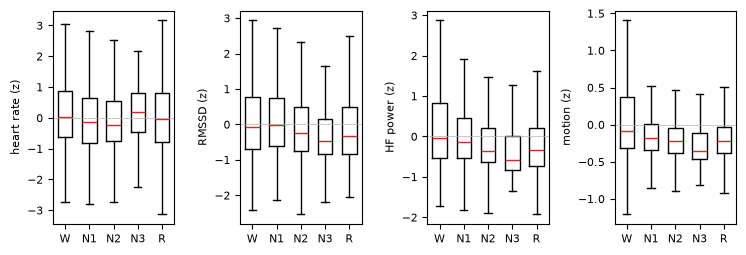

        hr_mean_z  rmssd_ms_z  hf_z  motion_z
stage5                                       
N1          -0.14       -0.02 -0.13     -0.18
N2          -0.22       -0.25 -0.36     -0.22
N3           0.18       -0.47 -0.57     -0.36
R           -0.03       -0.33 -0.33     -0.22
W            0.04       -0.08 -0.03     -0.08


In [4]:
order = ["W", "N1", "N2", "N3", "R"]
show = [("hr_mean_z", "heart rate (z)"), ("rmssd_ms_z", "RMSSD (z)"), ("hf_z", "HF power (z)"), ("motion_z", "motion (z)")]
fig, axes = plt.subplots(1, 4, figsize=(7.5, 2.6))
for ax, (c, lab) in zip(axes, show):
    data = [F.loc[F.stage5 == st, c].dropna().to_numpy() for st in order]
    ax.boxplot(data, showfliers=False, widths=0.6, medianprops={"color": "tab:red"})
    ax.set_xticks(range(1, 6)); ax.set_xticklabels(order); ax.set_ylabel(lab)
    ax.axhline(0, color="0.7", lw=0.5)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig_features_by_stage.png", dpi=150); plt.show()
print((F.groupby("stage5")[[c for c, _ in show]].median()).round(2).to_string())